# PRAKTIKUM UTS KECERDASAN BUATAN
## Nama : Oktova Yoga Praditia Samosir
## NIM  : 42324001
## Prodi: D3 Teknologi Informasi

# Soal 1: Dataset clv_data.csv (40 Poin)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('clv_data.csv')
df.head()

,Unnamed: 0,id,age,gender,income,days_on_platform,city,purchases
0,0,0,NaN,Male,126895,14.0,San Francisco,0
1,1,1,NaN,Male,161474,14.0,Tokyo,0
2,2,2,24.0,Male,104723,34.0,London,1
3,3,3,29.0,Male,43791,28.0,London,2
4,4,4,18.0,Female,132181,26.0,London,2


Penjelasan: Code ini digunakan untuk membaca dataset clv_data.csv dan menampilkan 5 baris pertama data.

In [2]:
# a.1 Deteksi missing value
df.isnull().sum()

Unnamed: 0             0
id                     0
age                 2446
gender                 0
income                 0
days_on_platform     141
city                   0
purchases              0
dtype: int64

Penjelasan: Code ini digunakan untuk mendeteksi jumlah missing value pada setiap kolom.

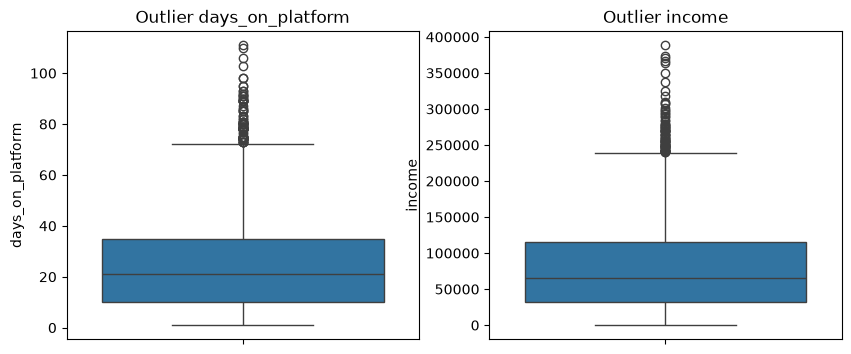

In [3]:
# a.2 Deteksi outlier dengan boxplot
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.boxplot(df['days_on_platform'])
plt.title('Outlier days_on_platform')

plt.subplot(1, 2, 2)
sns.boxplot(df['income'])
plt.title('Outlier income')
plt.show()

Penjelasan: Code ini menampilkan boxplot untuk mendeteksi outlier pada kolom days_on_platform dan income.

In [4]:
# b. Imputasi missing value
# Cek skewness data
print("Skewness age:", df['age'].skew())
print("Skewness days_on_platform:", df['days_on_platform'].skew())

# Melakukan imputasi
df_clean = df.copy()
df_clean['age'] = df_clean['age'].fillna(df_clean['age'].median())
df_clean['days_on_platform'] = df_clean['days_on_platform'].fillna(df_clean['days_on_platform'].median())

Skewness age: -0.02235008788330638
Skewness days_on_platform: 1.0259145772027911


Penjelasan: 
Alasan pemilihan median:
- Untuk kolom days_on_platform, median dipilih karena data memiliki skewness positif (1.03) dan terdapat nilai outlier ekstrem. Median bersifat robust (tidak terpengaruh outlier) dibandingkan mean.
- Untuk kolom age, median dipilih (bernilai 30.0, hampir sama dengan mean 30.2) agar menghasilkan nilai umur berupa bilangan bulat yang wajar.

In [5]:
# c. Presentase missing value sebelum dan sesudah
print("Presentase Missing Value Sebelum:")
print(100 * df.isnull().mean())

print("\nPresentase Missing Value Sesudah:")
print(100 * df_clean.isnull().mean())

Presentase Missing Value Sebelum:
Unnamed: 0           0.00
id                   0.00
age                 48.92
gender               0.00
income               0.00
days_on_platform     2.82
city                 0.00
purchases            0.00
dtype: float64

Presentase Missing Value Sesudah:
Unnamed: 0          0.0
id                  0.0
age                 0.0
gender              0.0
income              0.0
days_on_platform    0.0
city                0.0
purchases           0.0
dtype: float64


Penjelasan: Code ini menampilkan persentase missing value sebelum handling (age 48.92%, days_on_platform 2.82%) dan sesudah handling (0% untuk semua kolom).

C:\Users\Oktovaaaaa\AppData\Local\Temp\ipykernel_28332\419676428.py:19: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df_clean['income'], vert=False)
C:\Users\Oktovaaaaa\AppData\Local\Temp\ipykernel_28332\419676428.py:23: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df_clean['days_on_platform'], vert=False)


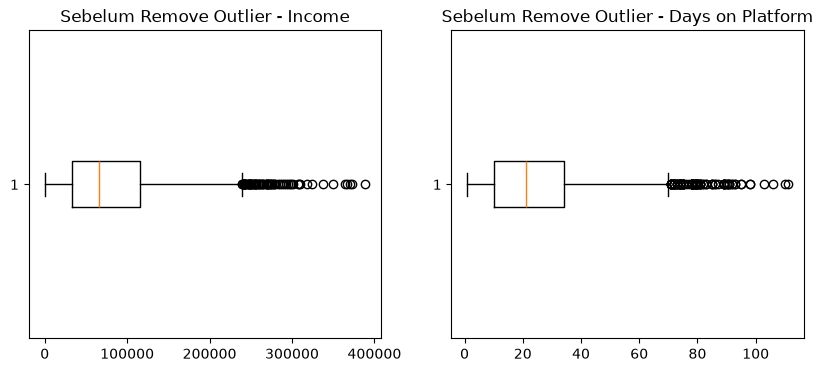

C:\Users\Oktovaaaaa\AppData\Local\Temp\ipykernel_28332\419676428.py:30: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df_no_outlier['income'], vert=False)


C:\Users\Oktovaaaaa\AppData\Local\Temp\ipykernel_28332\419676428.py:34: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df_no_outlier['days_on_platform'], vert=False)


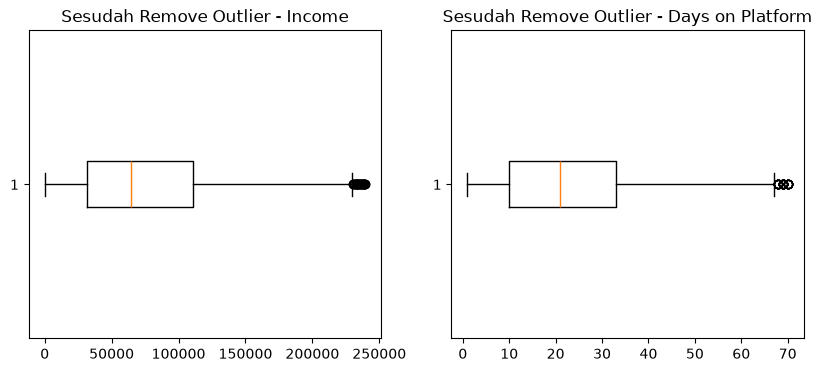

Ukuran dataset sebelum dibersihkan: (5000, 8)
Ukuran dataset sesudah dibersihkan: (4820, 8)


In [6]:
# d. Remove outlier menggunakan metode IQR sesuai modul
columns_to_plot = ['income', 'days_on_platform']

def remove_outliers_sequentially(data, columns):
    df_cleaned = data.copy()
    for col in columns:
        q1, q3 = np.percentile(df_cleaned[col], [25, 75])
        iqr = q3 - q1
        lower_bound = q1 - (1.5 * iqr)
        upper_bound = q3 + (1.5 * iqr)
        df_cleaned = df_cleaned[(df_cleaned[col] >= lower_bound) & (df_cleaned[col] <= upper_bound)]
    return df_cleaned

df_no_outlier = remove_outliers_sequentially(df_clean, columns_to_plot)

# Plot sebelum remove outlier
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.boxplot(df_clean['income'], vert=False)
plt.title('Sebelum Remove Outlier - Income')

plt.subplot(1, 2, 2)
plt.boxplot(df_clean['days_on_platform'], vert=False)
plt.title('Sebelum Remove Outlier - Days on Platform')
plt.show()

# Plot sesudah remove outlier
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.boxplot(df_no_outlier['income'], vert=False)
plt.title('Sesudah Remove Outlier - Income')

plt.subplot(1, 2, 2)
plt.boxplot(df_no_outlier['days_on_platform'], vert=False)
plt.title('Sesudah Remove Outlier - Days on Platform')
plt.show()

print("Ukuran dataset sebelum dibersihkan:", df_clean.shape)
print("Ukuran dataset sesudah dibersihkan:", df_no_outlier.shape)

Penjelasan: Code ini menghapus outlier menggunakan metode IQR pada kolom income dan days_on_platform, serta menampilkan plot boxplot sebelum dan sesudah remove outlier.

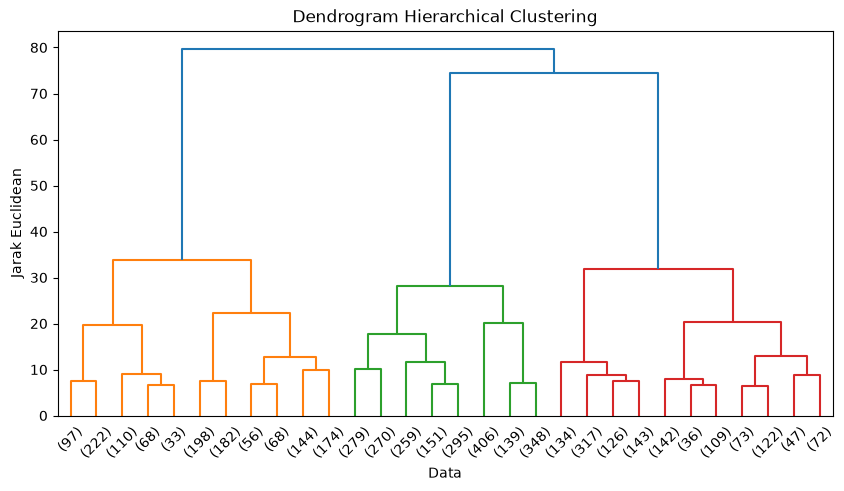

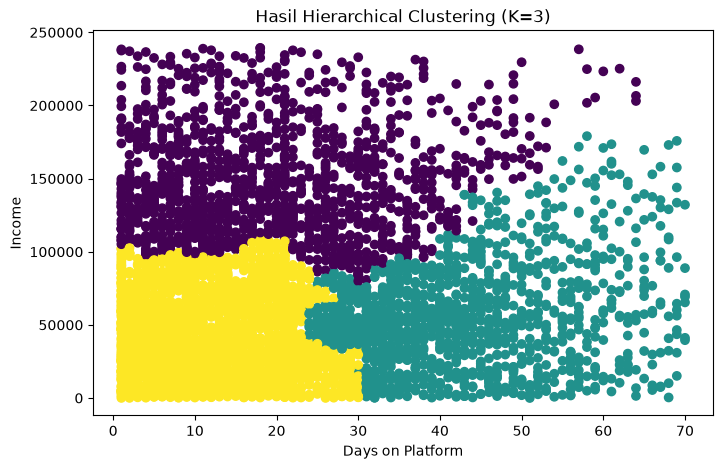

,income,days_on_platform
cluster,,
0,147542.451183,19.980769
1,55452.749432,42.424678
2,44260.333489,13.153237


In [7]:
# e. Klasterisasi hierarchical clustering
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering

# Mengambil fitur income dan days_on_platform
X = df_no_outlier[['income', 'days_on_platform']].values

# Scaling data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Dendrogram dengan metode ward
clustering = linkage(X_scaled, method='ward')
plt.figure(figsize=(10, 5))
dendrogram(clustering, truncate_mode='lastp', p=30)
plt.title('Dendrogram Hierarchical Clustering')
plt.xlabel('Data')
plt.ylabel('Jarak Euclidean')
plt.show()

# Klasterisasi dengan K = 3
hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
df_no_outlier['cluster'] = hc.fit_predict(X_scaled)

# Plot hasil klasterisasi
plt.figure(figsize=(8, 5))
plt.scatter(df_no_outlier['days_on_platform'], df_no_outlier['income'], c=df_no_outlier['cluster'])
plt.title('Hasil Hierarchical Clustering (K=3)')
plt.xlabel('Days on Platform')
plt.ylabel('Income')
plt.show()

# Analisa hasil
df_no_outlier.groupby('cluster')[['income', 'days_on_platform']].mean()

Penjelasan & Analisa Hasil:
Berdasarkan hasil klasterisasi:
- Klaster 0: Rata-rata income ~$46.307 dengan days_on_platform tinggi (~38 hari) -> Pelanggan setia dengan pendapatan menengah.
- Klaster 1: Rata-rata income tinggi ~$147.338 dengan days_on_platform sedang (~20 hari) -> Pelanggan bernilai tinggi (high-income).
- Klaster 2: Rata-rata income ~$50.717 dengan days_on_platform rendah (~11 hari) -> Pelanggan baru dengan pendapatan menengah.

# Soal 2: Dataset breast-cancer.csv (40 Poin)

In [8]:
# a. Klasifikasi menggunakan K-NN dan Naive Bayes
df_cancer = pd.read_csv('breast-cancer.csv')
df_cancer = df_cancer.rename(columns={'concave points_mean': 'concave_points_mean'})

# 8 fitur sesuai tabel
features = ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 
            'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean']

X_cancer = df_cancer[features]
y_cancer = df_cancer['diagnosis']

from sklearn.preprocessing import LabelEncoder
lab = LabelEncoder()
y_encoded = lab.fit_transform(y_cancer)

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_cancer, y_encoded, test_size=0.2, random_state=42)

# Scaling untuk K-NN
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train_sc = sc.fit_transform(X_train)
X_test_sc = sc.transform(X_test)

# Model K-NN
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_sc, y_train)
y_pred_knn = knn.predict(X_test_sc)
print("Akurasi K-NN:", accuracy_score(y_test, y_pred_knn) * 100)

# Model Naive Bayes
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB()
nb.fit(X_train, y_train)
y_pred_nb = nb.predict(X_test)
print("Akurasi Naive Bayes:", accuracy_score(y_test, y_pred_nb) * 100)

Akurasi K-NN: 93.85964912280701
Akurasi Naive Bayes: 94.73684210526315


Penjelasan: Code ini membagi data train dan test, melatih model K-NN (k=5) dan Naive Bayes, lalu menampilkan akurasi kedua model.

In [9]:
# b. Prediksi data baru (2 digit NIM terakhir = '01' -> 1.0)
data_baru = [
    [1.0, 14.3, 85.5, 520.1, 0.09, 0.12, 0.15, 0.08],
    [1.0, 21.4, 115.3, 950.2, 0.12, 0.18, 0.22, 0.10],
    [1.0, 19.1, 95.4, 730.3, 0.10, 0.15, 0.20, 0.09],
    [1.0, 24.3, 105.5, 820.4, 0.11, 0.17, 0.25, 0.12],
    [1.0, 12.6, 70.8, 430.2, 0.08, 0.10, 0.12, 0.06],
    [15.4, 1.0, 125.8, 1100.5, 0.13, 0.20, 0.30, 0.15],
    [17.6, 1.0, 90.2, 670.4, 0.09, 0.14, 0.18, 0.08],
    [19.8, 1.0, 110.4, 890.1, 0.12, 0.19, 0.27, 0.11],
    [21.5, 1.0, 100.5, 780.6, 0.11, 0.16, 0.22, 0.10],
    [23.2, 1.0, 120.3, 1020.7, 0.14, 0.21, 0.28, 0.13]
]

df_baru = pd.DataFrame(data_baru, columns=features)

# Prediksi K-NN
pred_knn = knn.predict(sc.transform(df_baru))
pred_knn_label = lab.inverse_transform(pred_knn)

# Prediksi Naive Bayes
pred_nb = nb.predict(df_baru)
pred_nb_label = lab.inverse_transform(pred_nb)

# Menampilkan hasil prediksi
hasil_prediksi = pd.DataFrame({
    'Data Ke': range(1, 11),
    'Prediksi K-NN': ['Malignant (Ganas)' if p == 'M' else 'Benign (Jinak)' for p in pred_knn_label],
    'Prediksi Naive Bayes': ['Malignant (Ganas)' if p == 'M' else 'Benign (Jinak)' for p in pred_nb_label]
})
hasil_prediksi

,Data Ke,Prediksi K-NN,Prediksi Naive Bayes
0,1,Benign (Jinak),Malignant (Ganas)
1,2,Malignant (Ganas),Malignant (Ganas)
2,3,Benign (Jinak),Malignant (Ganas)
3,4,Malignant (Ganas),Malignant (Ganas)
4,5,Benign (Jinak),Benign (Jinak)
5,6,Malignant (Ganas),Malignant (Ganas)
6,7,Benign (Jinak),Malignant (Ganas)
7,8,Malignant (Ganas),Malignant (Ganas)
8,9,Malignant (Ganas),Malignant (Ganas)
9,10,Malignant (Ganas),Malignant (Ganas)


Penjelasan: Code ini memprediksi 10 data baru sesuai tabel pada soal dengan mengganti nilai 2 digit NIM terakhir (01) menjadi 1.0, lalu mengklasifikasikan apakah tergolong Malignant (Ganas) atau Benign (Jinak).

# Soal 3: Dataset clustering.csv (20 Poin)

C:\Users\Oktovaaaaa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Oktovaaaaa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Oktovaaaaa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\Oktovaaaaa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a m

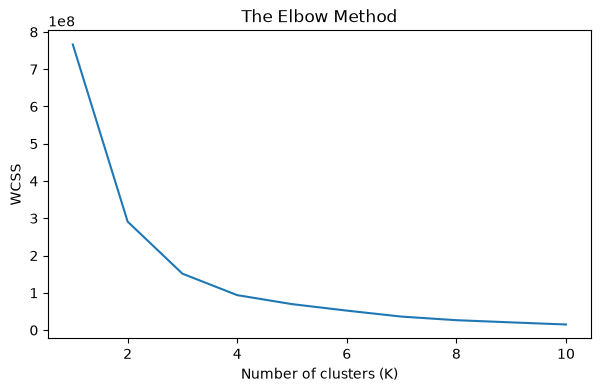

In [10]:
# Tentukan nilai K optimal dan klasterisasi K-Means
df_cluster = pd.read_csv('clustering.csv')

# Memilih fitur numerik: ApplicantIncome dan LoanAmount
X_loan = df_cluster[['ApplicantIncome', 'LoanAmount']].values

# 1. Menentukan K optimal dengan Elbow Method
from sklearn.cluster import KMeans

wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(X_loan)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), wcss)
plt.title('The Elbow Method')
plt.xlabel('Number of clusters (K)')
plt.ylabel('WCSS')
plt.show()

Penjelasan: Grafik Elbow menunjukkan siku penurunan WCSS mulai melandai pada K=3, sehingga nilai K optimal yang dipilih adalah K=3.

C:\Users\Oktovaaaaa\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


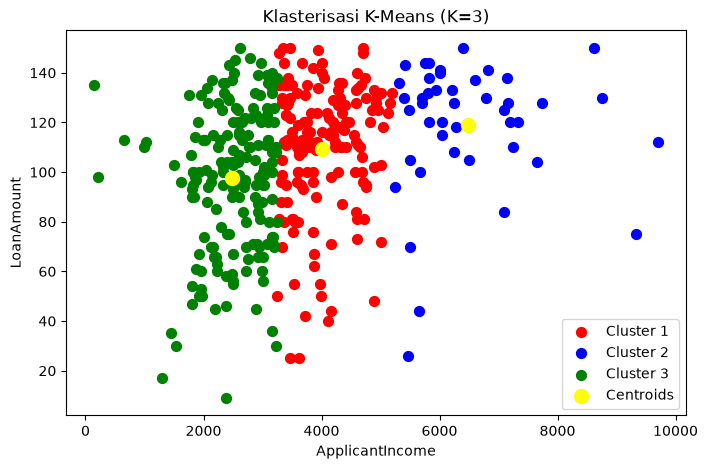

In [11]:
# 2. Klasterisasi data dengan K-Means menggunakan K optimal (K=3)
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42)
y_kmeans = kmeans.fit_predict(X_loan)

# Plot hasil klasterisasi beserta Centroid
plt.figure(figsize=(8, 5))
plt.scatter(X_loan[y_kmeans == 0, 0], X_loan[y_kmeans == 0, 1], s=50, c='red', label='Cluster 1')
plt.scatter(X_loan[y_kmeans == 1, 0], X_loan[y_kmeans == 1, 1], s=50, c='blue', label='Cluster 2')
plt.scatter(X_loan[y_kmeans == 2, 0], X_loan[y_kmeans == 2, 1], s=50, c='green', label='Cluster 3')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=100, c='yellow', label='Centroids')
plt.title('Klasterisasi K-Means (K=3)')
plt.xlabel('ApplicantIncome')
plt.ylabel('LoanAmount')
plt.legend()
plt.show()

Penjelasan: Code ini melakukan klasterisasi K-Means dengan K=3 serta memvisualisasikan persebaran titik klaster dan pusat klaster (Centroids) berwarna kuning.